In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import time
from pathlib import Path

device = torch.device("cpu")
print("Device:", device)

DATA = Path("../data/processed")

X_train = np.load(DATA / "elia_X_train.npy").reshape(-1, 24, 1).astype(np.float32)
X_val   = np.load(DATA / "elia_X_val.npy").reshape(-1, 24, 1).astype(np.float32)
X_test  = np.load(DATA / "elia_X_test.npy").reshape(-1, 24, 1).astype(np.float32)

y_train = np.load(DATA / "elia_y_train.npy").astype(np.float32)
y_val   = np.load(DATA / "elia_y_val.npy").astype(np.float32)
y_test  = np.load(DATA / "elia_y_test.npy").astype(np.float32)

print("X:", X_train.shape, X_val.shape, X_test.shape)
print("y:", y_train.shape, y_val.shape, y_test.shape)

Device: cpu
X: (33700, 24, 1) (7221, 24, 1) (7222, 24, 1)
y: (33700,) (7221,) (7222,)


In [2]:
class SupervisedLSTMAE(nn.Module):
    def __init__(self, input_size=1, hidden=32, latent=8):
        super().__init__()
        # Encoder
        self.encoder_lstm = nn.LSTM(input_size, hidden, batch_first=True)
        self.encoder_fc   = nn.Linear(hidden, latent)
        
        # Decoder (for reconstruction)
        self.decoder_fc   = nn.Linear(latent, hidden)
        self.decoder_lstm = nn.LSTM(hidden, input_size, batch_first=True)
        
        # Prediction head (supervised)
        self.predictor = nn.Sequential(
            nn.Linear(latent, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    
    def forward(self, x):
        # Encode
        _, (h, _) = self.encoder_lstm(x)
        z = self.encoder_fc(h.squeeze(0))            # (batch, latent)
        
        # Decode for reconstruction
        h_dec = self.decoder_fc(z).unsqueeze(1).repeat(1, 24, 1)
        recon, _ = self.decoder_lstm(h_dec)
        
        # Predict next hour
        pred = self.predictor(z).squeeze(-1)          # (batch,)
        
        return recon, z, pred

model = SupervisedLSTMAE(input_size=1, hidden=32, latent=8).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 5,333


In [3]:
batch_size = 256

train_ds = TensorDataset(
    torch.tensor(X_train),
    torch.tensor(y_train).unsqueeze(-1)
)
val_ds = TensorDataset(
    torch.tensor(X_val),
    torch.tensor(y_val).unsqueeze(-1)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 132, Val batches: 29


In [4]:
EPOCHS = 30
LR = 1e-3
ALPHA = 0.3   # weight for reconstruction
BETA  = 1.0   # weight for prediction (higher = more focused on downstream)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
mse = nn.MSELoss()

train_recon, train_pred, val_recon, val_pred = [], [], [], []

for epoch in range(EPOCHS):
    t0 = time.time()
    
    # --- Train ---
    model.train()
    r_sum, p_sum = 0.0, 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        recon, _, pred = model(xb)
        
        loss_recon = mse(recon, xb)
        loss_pred  = mse(pred, yb)
        loss = ALPHA * loss_recon + BETA * loss_pred
        
        loss.backward()
        optimizer.step()
        
        r_sum += loss_recon.item() * xb.size(0)
        p_sum += loss_pred.item()  * xb.size(0)
    
    tr_recon = r_sum / len(train_ds)
    tr_pred  = p_sum / len(train_ds)
    
    # --- Validate ---
    model.eval()
    r_sum, p_sum = 0.0, 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            recon, _, pred = model(xb)
            r_sum += mse(recon, xb).item() * xb.size(0)
            p_sum += mse(pred, yb).item()  * xb.size(0)
    
    va_recon = r_sum / len(val_ds)
    va_pred  = p_sum / len(val_ds)
    
    train_recon.append(tr_recon); train_pred.append(tr_pred)
    val_recon.append(va_recon);   val_pred.append(va_pred)
    
    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"recon {tr_recon:.6f}/{va_recon:.6f} | "
          f"pred  {tr_pred:.6f}/{va_pred:.6f} | "
          f"{time.time()-t0:.1f}s")

c:\Users\Lenovo\Desktop\EHMAH\CODE\Final Project\capstone\venv\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([256, 1])) that is different to the input size (torch.Size([256])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\Lenovo\Desktop\EHMAH\CODE\Final Project\capstone\venv\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([164, 1])) that is different to the input size (torch.Size([164])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\Lenovo\Desktop\EHMAH\CODE\Final Project\capstone\venv\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([53, 1])) that is different to the input size (torch.Size([53])). Th

Epoch  1/30 | recon 0.070624/0.033728 | pred  87787773.797982/85816983.083783 | 13.0s
Epoch  2/30 | recon 0.119827/0.143083 | pred  86095899.121187/82341819.473203 | 13.6s
Epoch  3/30 | recon 0.132026/0.143083 | pred  79851698.298872/73068149.839634 | 11.0s
Epoch  4/30 | recon 0.132026/0.143083 | pred  67166451.657685/57346838.841712 | 14.9s
Epoch  5/30 | recon 0.132026/0.143083 | pred  48969557.289496/37829107.069381 | 10.7s
Epoch  6/30 | recon 0.132026/0.143083 | pred  29401894.702908/19829701.291511 | 16.1s
Epoch  7/30 | recon 0.132026/0.143083 | pred  13916870.925341/8130373.718806 | 9.5s
Epoch  8/30 | recon 0.132026/0.143083 | pred  5448306.065223/3248076.094620 | 9.6s
Epoch  9/30 | recon 0.132026/0.143083 | pred  2489664.180861/2071178.595105 | 10.2s
Epoch 10/30 | recon 0.132026/0.143083 | pred  1854012.283220/1922999.512360 | 9.8s
Epoch 11/30 | recon 0.132026/0.143083 | pred  1768030.864451/1922901.252943 | 9.5s
Epoch 12/30 | recon 0.132026/0.143083 | pred  1759953.727997/192736

In [5]:
def extract_z(X_3d, model, batch_size=512):
    model.eval()
    feats = []
    with torch.no_grad():
        for i in range(0, len(X_3d), batch_size):
            batch = torch.tensor(X_3d[i:i+batch_size]).to(device)
            _, z, _ = model(batch)
            feats.append(z.cpu().numpy())
    return np.vstack(feats)

F_train = extract_z(X_train, model)
F_val   = extract_z(X_val,   model)
F_test  = extract_z(X_test,  model)

np.save(DATA / "elia_F_train_v3.npy", F_train)
np.save(DATA / "elia_F_val_v3.npy",   F_val)
np.save(DATA / "elia_F_test_v3.npy",  F_test)
torch.save(model.state_dict(), "../models/lstm_autoencoder_v3.pt")

print("F_train:", F_train.shape)

F_train: (33700, 8)


In [6]:
from sklearn.ensemble import RandomForestRegressor

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

rf = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(F_train, y_train)
pred = rf.predict(F_test)

print(f"Supervised AE (8 features): MAPE {mape(y_test, pred):.4f}%")
print(f"Raw (24 features):          MAPE 1.5023%")
print(f"Plain AE v1 (8 features):   MAPE 2.5583%")
print(f"Plain AE v2 (16 features):  MAPE 3.5932%")

Supervised AE (8 features): MAPE 3.2606%
Raw (24 features):          MAPE 1.5023%
Plain AE v1 (8 features):   MAPE 2.5583%
Plain AE v2 (16 features):  MAPE 3.5932%


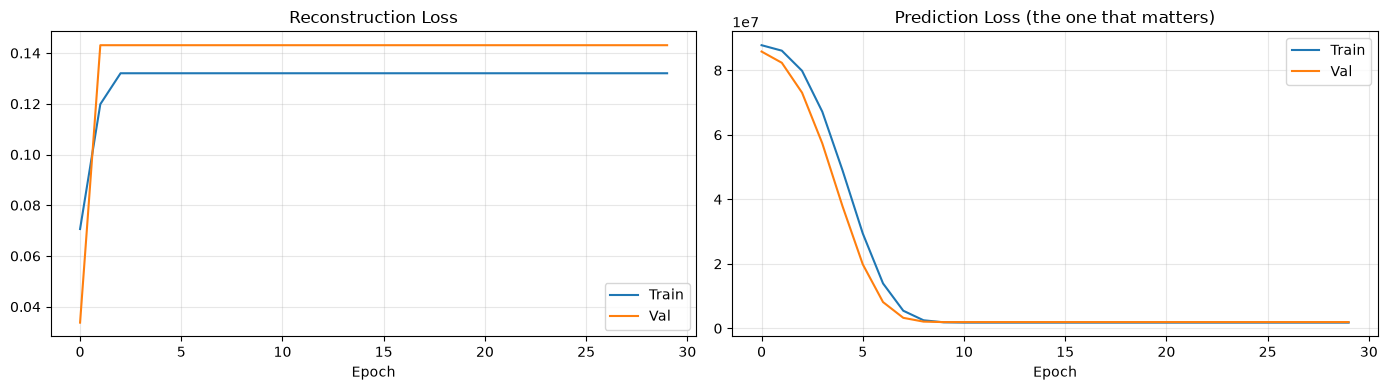

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(train_recon, label="Train")
axes[0].plot(val_recon, label="Val")
axes[0].set_title("Reconstruction Loss")
axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(train_pred, label="Train")
axes[1].plot(val_pred, label="Val")
axes[1].set_title("Prediction Loss (the one that matters)")
axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../data/processed/supervised_ae_loss.png", dpi=150, bbox_inches="tight")
plt.show()